# makemore part 2: MLP

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
words = open("/kaggle/input/datasets/salahbouakaz/names-txt/names.txt","r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

## Data

In [4]:
chars = sorted(list(set("".join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi["."] = 0
print(stoi)
itos = {i:s for s,i in stoi.items()}

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}


In [5]:
block_size = 3
X, Y = [], []
for w in words[:5]:
    print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        print(''.join(itos[i] for i in context), '->', itos[ix])
        context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

emma
... -> e
..e -> m
.em -> m
emm -> a
mma -> .
olivia
... -> o
..o -> l
.ol -> i
oli -> v
liv -> i
ivi -> a
via -> .
ava
... -> a
..a -> v
.av -> a
ava -> .
isabella
... -> i
..i -> s
.is -> a
isa -> b
sab -> e
abe -> l
bel -> l
ell -> a
lla -> .
sophia
... -> s
..s -> o
.so -> p
sop -> h
oph -> i
phi -> a
hia -> .


## Model v1 (2-D embedding, 100 hidden)

In [6]:
g = torch.Generator().manual_seed(2147483647)

In [7]:
C = torch.randn((27,2), generator=g)
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [8]:
w1 = torch.randn((6,100), generator=g)
b1 = torch.randn((100), generator=g)

In [9]:
h = torch.tanh(emb.view(-1, 6) @ w1 + b1)
h

tensor([[-0.9348,  1.0000,  0.9258,  ...,  0.9786, -0.1926,  0.9515],
        [ 0.2797,  0.9997,  0.7675,  ...,  0.9929,  0.9992,  0.9981],
        [-0.9960,  1.0000, -0.8694,  ..., -0.5159, -1.0000, -0.0069],
        ...,
        [-0.9996,  1.0000, -0.9273,  ..., -0.9999, -0.9974, -0.9970],
        [-0.9043,  1.0000,  0.9868,  ..., -0.7859, -0.4819,  0.9981],
        [-0.9048,  1.0000,  0.9553,  ...,  0.9866,  1.0000,  0.9907]])

In [10]:
w2 = torch.randn((100,27), generator=g)
b2 = torch.randn((27), generator=g)

In [11]:
parameters = [C, w1, b1, w2, b2]
sum(p.nelement() for p in parameters)

3481

In [12]:
logits = h @ w2 + b2
logits.shape

torch.Size([32, 27])

In [13]:
counts = logits.exp()
probs = counts/counts.sum(1, keepdim=True)
probs.shape

torch.Size([32, 27])

In [14]:
loss = -probs[torch.arange(32),Y].log().mean()
loss

tensor(17.7697)

In [15]:
F.cross_entropy(logits, Y)

tensor(17.7697)

In [16]:
block_size = 3
X, Y = [], []
for w in words:
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

## Divided Data (80%/10%/10%)

In [20]:
# build the dataset
# training split, dev/validation split, test split
# 80%, 10%, 10%
block_size = 3

def build_dataset(words):  
  X, Y = [], []
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] 

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [21]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
w1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
w2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]
sum(p.nelement() for p in parameters)

3481

In [22]:
for p in parameters:
    p.requires_grad = True

## Learning-rate sweep

In [23]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
lrs[:10].tolist()

[0.0010000000474974513,
 0.001006938866339624,
 0.0010139254154637456,
 0.0010209609754383564,
 0.0010280447313562036,
 0.0010351781966164708,
 0.0010423606727272272,
 0.0010495934402570128,
 0.0010568759171292186,
 0.0010642095003277063]

In [24]:
lri = []
lossi = []
for i in range(1000):
    #mini batch
    ix = torch.randint(0, Xtr.shape[0],(32,))
    #forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 6) @ w1 + b1)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    if i % 100 == 0:
        print(loss.item())
    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad
    #track stats
    lri.append(lre[i])
    lossi.append(loss.item())


17.19329261779785
18.842323303222656
13.816529273986816
10.042511940002441
6.901478290557861
5.404200077056885
3.5962376594543457
2.814772844314575
3.228914737701416
4.270458221435547


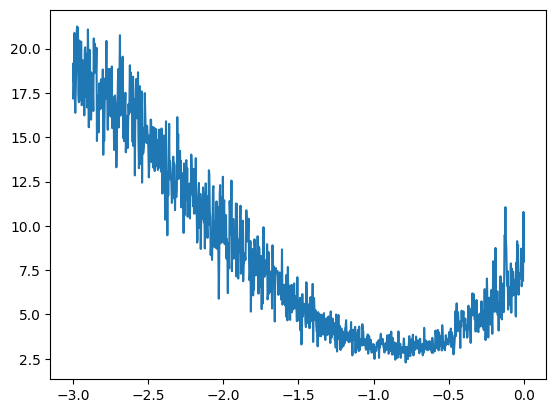

In [25]:
plt.plot(lri, lossi)

### best lr ≈ 0.1

## Train v1

In [26]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
w1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
w2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]
sum(p.nelement() for p in parameters)

3481

In [27]:
for p in parameters:
    p.requires_grad = True

In [28]:
for i in range(10000):
    #mini batch
    ix = torch.randint(0, Xtr.shape[0],(32,))
    #forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 6) @ w1 + b1)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    if i % 1000 == 0:
        print(loss.item())
    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    for p in parameters:
        p.data += -0.1 * p.grad


18.331684112548828
2.7821738719940186
2.5686604976654053
2.928818464279175
2.8292384147644043
2.2166757583618164
2.2349486351013184
2.4799606800079346
2.242081880569458
2.290631055831909


In [29]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 6) @ w1 + b1)
logits = h @ w2 + b2
loss = F.cross_entropy(logits, Ydev)
loss.item()

2.5015270709991455

## Embedding plot (2-D)

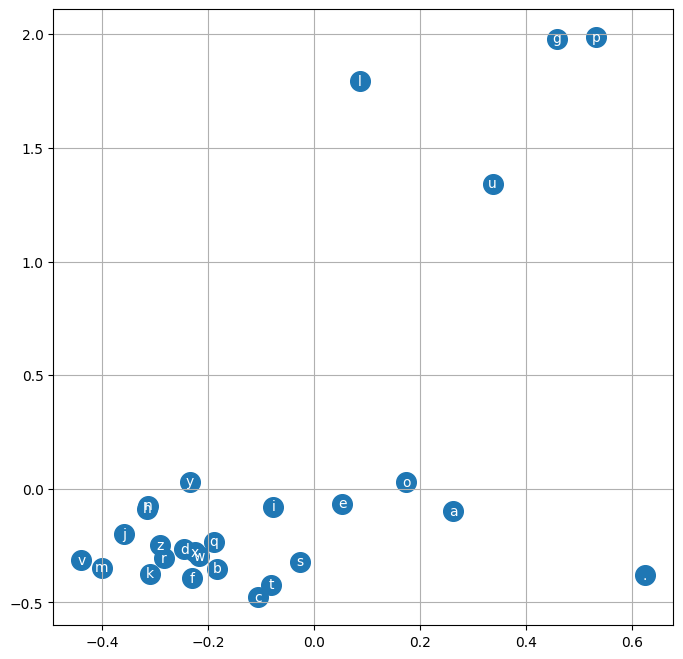

In [30]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

## Model v2 (10-D, 250 hidden)

In [31]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
w1 = torch.randn((30, 250), generator=g)
b1 = torch.randn(250, generator=g)
w2 = torch.randn((250, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]
sum(p.nelement() for p in parameters)

14797

In [32]:
for p in parameters:
    p.requires_grad = True

In [33]:
lossi = []
stepi = []
lr = 0.1
for i in range(200000):
    #mini batch
    ix = torch.randint(0, Xtr.shape[0],(32,))
    #forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 30) @ w1 + b1)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    if i % 20000 == 0:
        lr -= 0.01
        print(loss.item())
    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    for p in parameters:
        p.data += -lr * p.grad
    #track stats
    lossi.append(loss.item())
    stepi.append(i)

27.126110076904297
2.595197916030884
2.40910005569458
2.5821187496185303
2.6747021675109863
2.3464150428771973
2.3055970668792725
2.169323444366455
2.069760322570801
1.6953696012496948


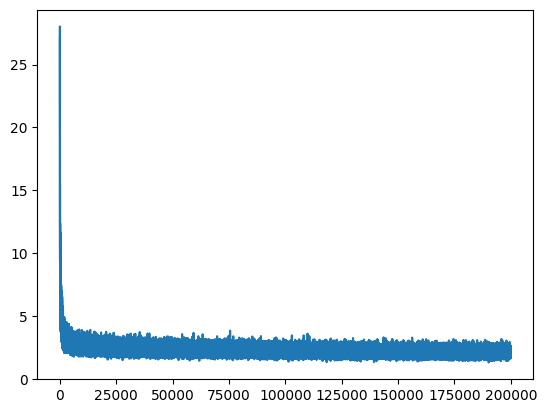

In [34]:
plt.plot(stepi,lossi)

In [35]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ w1 + b1)
logits = h @ w2 + b2
loss = F.cross_entropy(logits, Ydev)
loss.item()

2.1922459602355957

## Model v3 (12-D, 350 hidden)

In [36]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 12), generator=g)
w1 = torch.randn((36, 350), generator=g)
b1 = torch.randn(350, generator=g)
w2 = torch.randn((350, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]
sum(p.nelement() for p in parameters)

22751

In [37]:
for p in parameters:
    p.requires_grad = True

In [38]:
lossi = []
stepi = []
lr = 0.4
for i in range(150000):
    #mini batch
    ix = torch.randint(0, Xtr.shape[0],(32,))
    #forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 36) @ w1 + b1)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    if i % 15000 == 0:
        lr -= 0.037
        print(loss.item())
    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    for p in parameters:
        p.data += -lr * p.grad
    #track stats
    lossi.append(loss.item())
    stepi.append(i)

36.76511001586914
6.499993324279785
4.069745063781738
3.895782947540283
3.141066074371338
3.1976795196533203
2.929675817489624
2.56866717338562
2.020124912261963
2.0048680305480957


In [39]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 36) @ w1 + b1)
logits = h @ w2 + b2
loss = F.cross_entropy(logits, Ydev)
loss.item()

2.1796374320983887

## Results table

| Model | Embedding | Hidden | Params | Dev loss |
| :--- | :---: | :---: | :---: | :---: |
| v1 | 2 | 100 | 3,481 | 2.5015 |
| v2 | 10 | 250 | 14,797 | 2.1922 |
| v3 | 12 | 350 | 22,751 | 2.1796 |

## Final test evaluation (once)

In [40]:
emb = C[Xte]
h = torch.tanh(emb.view(-1, 36) @ w1 + b1)
logits = h @ w2 + b2
loss = F.cross_entropy(logits, Yte)
loss.item()

2.178565263748169

## Sampling

In [41]:
g = torch.Generator().manual_seed(2147483647)
for _ in range(10):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ w1 + b1)
        logits = h @ w2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix==0:
            break

    print("".join(itos[i] for i in out))

celie.
corly.
railah.
taharlonimitta.
nylandra.
andr.
samiyah.
jaxsiya.
tai.
mazie.
